- 全村的希望
- 原始代码，未改

In [1]:
import time
import math
import torch
import random
import numpy as np
import torch.nn as nn
import torch.optim as optim
from tqdm.notebook import tqdm
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.optim import lr_scheduler
import matplotlib.patches as patches
from matplotlib.patches import Ellipse
from typing import Dict, Optional, Tuple, Union
from dataclasses import dataclass, field
from collections import defaultdict

from utils.metrics import PIVmetric
from utils.visualizer import plot_flow_field
from Cmax import ContrastMaximizationLoss

# 数据加载：事件、光流
from data_processor import Events_to_voxelgrid, Events_to_EST
from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager
from utils.metrics import PIVmetric
# 检查CUDA是否可用
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


tensor(9.5859e-06, device='cuda:0') tensor(3.0000, device='cuda:0')
原始事件:torch.Size([566585, 4])
当前使用的事件数量:torch.Size([340160, 4])
最大速度值: 5.000658988952637


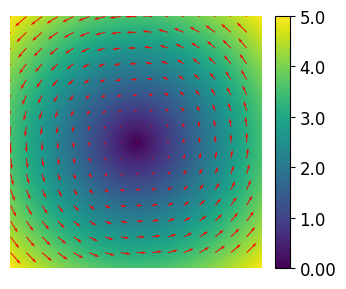

In [2]:
max_v = 5

flow0 = FlowManager(mode="analytical", name="solid_rot", x_c=128, y_c=128, omega=0.005525*max_v)
flow1 = FlowManager(mode="analytical", name="cellular_flow", vmax=max_v, p=256)
flow2 = FlowManager(mode="analytical", name="sin_flow", x_c=128,y_c=128, a=16, b=128, scale=max_v)
flow3 = FlowManager(mode="analytical", name="uniform", uc=max_v/np.sqrt(2), vc=max_v/np.sqrt(2))
flow4 = FlowManager(mode="data", data_path="./data/JHTDB_isotropic1024_hd_00001_flow.npz")
flow5 = FlowManager(mode="data", data_path="./data/JHTDB_mhd1024_hd_00001_flow.npz")
flow6 = FlowManager(mode="data", data_path="./data/backstep_Re1500_00001_flow.npz")
flow7 = FlowManager(mode="data", data_path="./data/cylinder_Re300_00001_flow.npz")
flow8 = FlowManager(mode="data", data_path="./data/DNS_turbulence_00001_flow.npz")

flow9 = FlowManager(mode="analytical", name="lamb_oseen", x_c=128, y_c=128, Gamma=3e3, rc=60)
flow10 = FlowManager(mode="analytical", name="shear_flow", vmax=max_v, p=256)
flow11 = FlowManager(mode="analytical", name="abc", max_v=max_v, ratio=2, k=None)
flow12 = FlowManager(mode="analytical", name="rf_flow", max_v=5.0, n_modes=20, seed=4)
flow13 = FlowManager(mode="analytical", name="gs_flow", max_v=5.0, n_vortex=20, seed=1)

flow_func = flow0.evaluate
cfg_evts = config_events()
cfg_evts.time_length=5
cfg_evts.d = 0.5
cfg_evts.density = 0.05

event_loader = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func)
evts, (u, v) = event_loader.load()
flowgt = torch.stack([v, u], dim=0).to(device)

events = evts[(evts[:, 2] > 0) & (evts[:, 2] < 3)]
print(events[:, 2].min(), events[:, 2].max())

u_gt = u.cpu().numpy()
v_gt = v.cpu().numpy()

print(f"原始事件:{evts.shape}")
print(f"当前使用的事件数量:{events.shape}")
print(f"最大速度值: {torch.max(torch.sqrt(u**2 + v** 2)).item()}")

plot_flow_field(u, v, output_file=None, colorbar_flag=True, step=1, quiver_step=16, scale=None, figsize=(5, 3))

Calculated Loss: -6.854931354522705


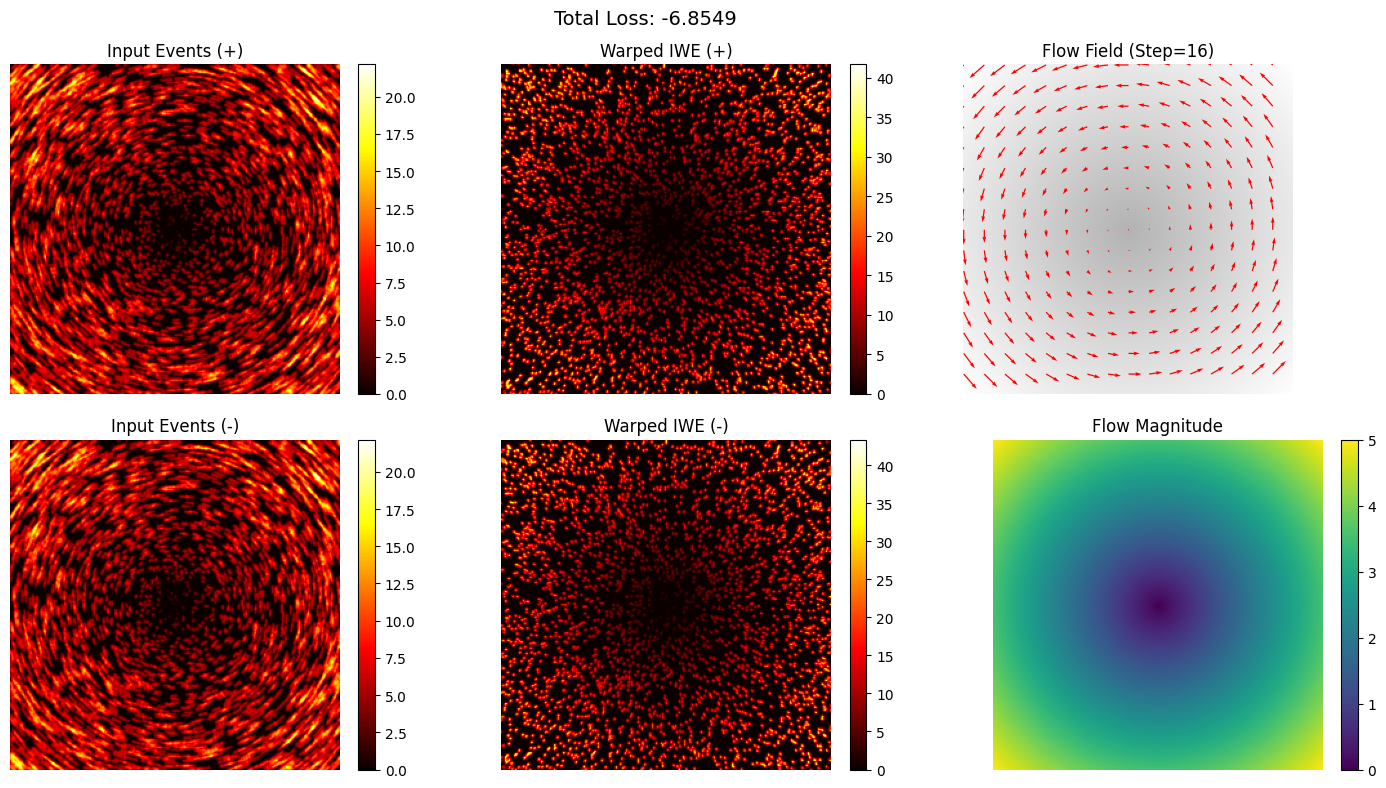

In [3]:
cmax_loss = ContrastMaximizationLoss(loss_type='l2_max', sigma=0.5, kernel_size=3).to(device)  # variance, l2_max, structure
loss = cmax_loss(events, flowgt, (256, 256), vis=True)
print(f"Calculated Loss: {loss.item()}")
# --- 可视化 ---
cmax_loss.plot_visualization(grid_step=16, grid_loss_n=None)

In [4]:
class GaussianSpatialIndexer:
    def __init__(
        self,
        means,
        scales,
        rotations,
        domain_size,
        tile_size,
        truncation_sigma=4.0,
        max_tile_span=16
    ):
        self.means = means
        self.scales = scales
        self.rotations = rotations.reshape(-1, 1)
        self.H, self.W = domain_size
        self.tile_size = tile_size
        self.truncation_sigma = truncation_sigma
        self.max_tile_span = max_tile_span
        self.device = means.device

        self.grid_h = (self.H + tile_size - 1) // tile_size
        self.grid_w = (self.W + tile_size - 1) // tile_size
        self.num_tiles = self.grid_h * self.grid_w

        self.cell_indices = torch.empty(0, dtype=torch.long, device=self.device)
        self.cell_ptr = torch.zeros(self.num_tiles + 1, dtype=torch.long, device=self.device)

        self.build()

    def build(self):
        N = self.means.shape[0]
        device = self.device

        if N == 0:
            return

        cos_t = torch.cos(self.rotations.squeeze(-1))
        sin_t = torch.sin(self.rotations.squeeze(-1))
        s_y, s_x = self.scales[:, 0], self.scales[:, 1]

        sigma_yy = (s_y * cos_t)**2 + (s_x * sin_t)**2
        sigma_xx = (s_y * sin_t)**2 + (s_x * cos_t)**2

        radius_y = self.truncation_sigma * torch.sqrt(sigma_yy)
        radius_x = self.truncation_sigma * torch.sqrt(sigma_xx)

        min_y = self.means[:, 0] - radius_y   # 允许为负
        max_y = self.means[:, 0] + radius_y   # 允许超过H
        min_x = self.means[:, 1] - radius_x
        max_x = self.means[:, 1] + radius_x
    
        # tile坐标映射后，裁剪到合法tile范围（而不是像素范围）
        rect_min_row = (min_y / self.tile_size).floor().long().clamp(0, self.grid_h - 1)
        rect_max_row = (max_y / self.tile_size).ceil().long().clamp(0, self.grid_h - 1)  # ✅ ceil
        rect_min_col = (min_x / self.tile_size).floor().long().clamp(0, self.grid_w - 1)
        rect_max_col = (max_x / self.tile_size).ceil().long().clamp(0, self.grid_w - 1)  # ✅ ceil
    
        # valid_mask里去掉对范围的判断，只保留span判断
        rows = rect_max_row - rect_min_row + 1
        cols = rect_max_col - rect_min_col + 1
        valid_mask = (
            (rows <= self.max_tile_span) &
            (cols <= self.max_tile_span) &
            (rows > 0) &
            (cols > 0)
        )

        if valid_mask.sum() == 0:
            return

        rect_min_row = rect_min_row[valid_mask]
        rect_max_row = rect_max_row[valid_mask]
        rect_min_col = rect_min_col[valid_mask]
        rect_max_col = rect_max_col[valid_mask]
        rows = rows[valid_mask]
        cols = cols[valid_mask]

        original_indices = torch.arange(N, device=device)[valid_mask]

        max_h_span = rows.max().item()
        max_w_span = cols.max().item()

        y_off = torch.arange(max_h_span, device=device)
        x_off = torch.arange(max_w_span, device=device)

        grid_rows = rect_min_row[:, None, None] + y_off[None, :, None]
        grid_cols = rect_min_col[:, None, None] + x_off[None, None, :]

        grid_rows = grid_rows.expand(-1, -1, max_w_span)
        grid_cols = grid_cols.expand(-1, max_h_span, -1)

        mask = (
            (grid_rows <= rect_max_row[:, None, None]) &
            (grid_cols <= rect_max_col[:, None, None])
        )

        valid_rows = grid_rows[mask]
        valid_cols = grid_cols[mask]

        gaussian_ids_expanded = original_indices[:, None, None].expand(-1, max_h_span, max_w_span)
        valid_gaussian_ids = gaussian_ids_expanded[mask]

        tile_ids = valid_rows * self.grid_w + valid_cols
        order = torch.argsort(tile_ids)
        tile_ids_sorted = tile_ids[order]

        self.cell_indices = valid_gaussian_ids[order]

        self.cell_ptr = torch.zeros(self.num_tiles + 1, dtype=torch.long, device=device)

        if tile_ids_sorted.numel() > 0:
            unique_ids, counts = torch.unique_consecutive(tile_ids_sorted, return_counts=True)
            self.cell_ptr.index_add_(0, unique_ids + 1, counts)
            torch.cumsum(self.cell_ptr, dim=0, out=self.cell_ptr)

In [5]:
class GaussianVelocityField_Tiled(nn.Module):
    """
    基于高斯的稠密光流场生成器 (Tiled + 向量化版本)
      1. indexer缓存：rebuild_indexer()在optimizer.step()后调用，forward不再重建
      2. 向量化tile循环：所有tile批量einsum，消除Python for循环
      3. Step2完全向量化：slot_offsets/all_gids无Python循环
      4. detach+clone：rebuild_indexer不持有计算图引用
    """
    def __init__(self, num_gaussians, H, W, tile_size=32, events=events, enable_jacobian=True, device=device):
        super().__init__()
        self.num_gaussians = num_gaussians
        self.H = H
        self.W = W
        self.tile_size = tile_size
        self.enable_jacobian = enable_jacobian
        self.device=device

        # 参数定义（[y, x] 顺序）
        if events is not None:
            mu_init = self.initialize_gaussian_positions(events, H, W, num_gaussians, 0)
            self.mu = nn.Parameter(mu_init)
        else:
            self.mu = nn.Parameter(torch.rand(num_gaussians, 2) * (H + 32) - 16)

        self.log_scale = nn.Parameter(torch.stack([torch.rand(num_gaussians) * np.log(15.0), torch.rand(num_gaussians) * np.log(10.0)], dim=1))
        self.opacity_logit = nn.Parameter(torch.zeros(num_gaussians, 1))
        self.rotation      = nn.Parameter(torch.rand(num_gaussians, 1) * torch.pi)
        self.local_velocity = nn.Parameter(torch.randn(num_gaussians, 2))

        if enable_jacobian:
            self.J_params = nn.Parameter(0.03 * torch.randn(num_gaussians, 3, device=device))
        else:
            self.register_parameter("J_params", None)

        self._indexer_cache = None

    def initialize_gaussian_positions(self, events, H, W, num_gaussians, alpha):
        with torch.no_grad():
            event_map = torch.zeros(H, W, device=self.device)
            xs = events[:,1].long().clamp(0, W-1)
            ys = events[:,0].long().clamp(0, H-1)
            event_map.index_put_((ys, xs), torch.ones_like(xs, dtype=torch.float32),accumulate=True)
    
            # 平滑
            event_map = F.avg_pool2d(event_map[None,None], kernel_size=9, stride=1, padding=4).squeeze()
    
            # log smoothing (稳定很多)
            event_map = torch.log1p(event_map)
            event_map_norm = event_map / (event_map.sum() + 1e-8)
            uniform = torch.ones_like(event_map) / (H * W)
            density = alpha * event_map_norm + (1 - alpha) * uniform
            flat = density.reshape(-1)

            sampled_idx = torch.multinomial(flat, num_gaussians, replacement=True)
    
            mu_y = (sampled_idx // W).float()
            mu_x = (sampled_idx % W).float()
    
            noise = 0.5
            mu_y += torch.randn_like(mu_y) * noise
            mu_x += torch.randn_like(mu_x) * noise
    
            mu = torch.stack([mu_y, mu_x], dim=1)
    
        return mu

    def rebuild_indexer(self):
        """
        在每次 optimizer.step() 之后调用。
        使用 detach+clone 确保不持有计算图引用。
        """
        with torch.no_grad():
            log_s_clamped = self.log_scale.clamp(min=np.log(1), max=np.log(self.H / 6))
            scales = torch.exp(log_s_clamped).detach().clone()
            self._indexer_cache = GaussianSpatialIndexer(
                self.mu.detach().clone(),
                scales,
                self.rotation.detach().clone(),
                (self.H, self.W),
                self.tile_size
            )

    #  协方差计算
    def compute_covariance_inv_and_R(self):
        log_s_clamped = self.log_scale.clamp(min=np.log(0.5), max=np.log(self.H / 6))
        s = torch.exp(log_s_clamped)
        r = self.rotation.squeeze(-1)
        cos_r = torch.cos(r)
        sin_r = torch.sin(r)

        R = torch.stack([
            torch.stack([cos_r, -sin_r], dim=-1),
            torch.stack([sin_r,  cos_r], dim=-1)
        ], dim=-2)

        inv_s2 = 1.0 / (s**2 + 1e-6)
        S_inv_mat = torch.diag_embed(inv_s2)
        Sigma_inv = torch.bmm(R, torch.bmm(S_inv_mat, R.transpose(1, 2)))
        return Sigma_inv, R, s

    def forward(self, rebuild_index=False):
        """
        rebuild_index=True  → 强制本次重建（首次调用或调试用）
        rebuild_index=False → 使用缓存indexer（正常训练路径）
        """
        device = self.mu.device

        # ── 使用缓存indexer ────────────────────────────────────
        if rebuild_index or self._indexer_cache is None:
            self.rebuild_indexer()
        indexer = self._indexer_cache

        # ── 预计算高斯属性 ─────────────────────────────────────
        Sigma_inv, R, scales = self.compute_covariance_inv_and_R()
        opacity  = torch.sigmoid(self.opacity_logit)
        v_global = torch.matmul(R, self.local_velocity.unsqueeze(-1)).squeeze(-1)

        if self.enable_jacobian and self.J_params is not None:
            a, b, c = self.J_params.unbind(-1)
            J_local = torch.stack([
                torch.stack([a,  b], dim=-1),
                torch.stack([c, -a], dim=-1)
            ], dim=-2)
            J = torch.bmm(R, torch.bmm(J_local, R.transpose(1, 2)))
        else:
            J = torch.zeros(self.num_gaussians, 2, 2, device=device)

        # ── 输出画布 ───────────────────────────────────────────
        final_vel_map = torch.zeros(2, self.H, self.W, device=device)
        weight_map    = torch.zeros(1, self.H, self.W, device=device)

        # ── Step 1: Active tiles ───────────────────────────────
        tile_counts     = indexer.cell_ptr[1:] - indexer.cell_ptr[:-1]  # [num_tiles]
        active_tile_ids = torch.where(tile_counts > 0)[0]                # [T]
        T = active_tile_ids.shape[0]
        if T == 0:
            return (torch.zeros(2, self.H, self.W, device=device), torch.zeros(1, self.H, self.W, device=device))

        K_max = tile_counts[active_tile_ids].max().item()
        P     = self.tile_size * self.tile_size

        # ── Step 2: 构建padded高斯索引 [T, K_max]（完全向量化）─
        starts = indexer.cell_ptr[active_tile_ids].detach()      # [T]
        ends   = indexer.cell_ptr[active_tile_ids + 1].detach()  # [T]
        counts = (ends - starts).detach()                        # [T]

        total   = counts.sum().item()
        iota    = torch.arange(total, device=device)

        # 每段起始的全局偏移 [T]
        cum_counts    = torch.cat([
            torch.zeros(1, dtype=torch.long, device=device),
            counts.cumsum(0)[:-1]
        ])
        slot_tile_idx = torch.repeat_interleave(
            torch.arange(T, device=device), counts)              # [total]
        slot_offsets  = iota - cum_counts[slot_tile_idx]         # [total]

        # cell_indices的连续区间索引（无Python循环）
        seg_starts = starts.repeat_interleave(counts)            # [total]
        seg_iota   = iota - torch.repeat_interleave(cum_counts, counts)
        all_gids   = indexer.cell_indices[seg_starts + seg_iota].detach()  # [total]

        padded_gids = torch.zeros(T, K_max, dtype=torch.long, device=device)
        valid_gmask = torch.zeros(T, K_max, dtype=torch.bool,  device=device)
        padded_gids[slot_tile_idx, slot_offsets] = all_gids
        valid_gmask[slot_tile_idx, slot_offsets] = True

        # ── Step 3: Gather高斯参数 [T, K_max, ...] ────────────
        flat_ids      = padded_gids.reshape(-1)
        cur_mu        = self.mu[flat_ids].reshape(T, K_max, 2)
        cur_sigma_inv = Sigma_inv[flat_ids].reshape(T, K_max, 2, 2)
        cur_opacity   = opacity[flat_ids].reshape(T, K_max, 1)
        cur_v_base    = v_global[flat_ids].reshape(T, K_max, 2)
        cur_J         = J[flat_ids].reshape(T, K_max, 2, 2)

        # ── Step 4: 构建像素坐标 [T, P, 2] ────────────────────
        tile_rows = active_tile_ids // indexer.grid_w
        tile_cols = active_tile_ids  % indexer.grid_w
        y_starts  = tile_rows * self.tile_size
        x_starts  = tile_cols * self.tile_size

        dy = torch.arange(self.tile_size, device=device, dtype=torch.float32)
        dx = torch.arange(self.tile_size, device=device, dtype=torch.float32)
        local_y, local_x = torch.meshgrid(dy, dx, indexing='ij')
        local_coords = torch.stack([local_y, local_x], dim=-1).reshape(1, P, 2)

        tile_origins = torch.stack([
            y_starts.float(), x_starts.float()
        ], dim=-1).unsqueeze(1)                                  # [T, 1, 2]
        pixel_coords = tile_origins + local_coords               # [T, P, 2]

        # 边界tile：标记超出图像范围的像素
        pixel_valid = (
            (pixel_coords[..., 0] < self.H) &
            (pixel_coords[..., 1] < self.W)
        )                                                        # [T, P]

        pixel_coords = torch.where(
            pixel_valid.unsqueeze(-1),
            pixel_coords,
            tile_origins.expand_as(pixel_coords)
        )

        # ── Step 5: delta [T, P, K_max, 2] ────────────────────
        delta = pixel_coords.unsqueeze(2) - cur_mu.unsqueeze(1)

        # ── Step 6: Mahalanobis distance [T, P, K_max] ────────
        term = torch.einsum('tpki, tkij, tpkj -> tpk', delta, cur_sigma_inv, delta)

        # ── Step 7: 权重 [T, P, K_max, 1] ────────────────────
        soft_mask = torch.sigmoid(-2.0 * (term - 14.0))  # 从term=12开始衰减，16处约0.12
        weights = (
            cur_opacity.unsqueeze(1)
            * torch.exp(-0.5 * term).unsqueeze(-1)
            * soft_mask.unsqueeze(-1)
            * valid_gmask[:, None, :, None].float()
            * pixel_valid[:, :, None, None].float()
        )

        # ── Step 8: 仿射速度 + 加权聚合 ───────────────────────
        v_affine   = torch.einsum('tkij, tpkj -> tpki', cur_J, delta)  # [T,P,K,2]
        v_tile_all = cur_v_base.unsqueeze(1) + v_affine                 # [T,P,K,2]

        weighted_vel = (weights * v_tile_all).sum(dim=2)         # [T, P, 2]
        weight_sum   = weights.sum(dim=2)                        # [T, P, 1]

        # ── Step 9: scatter_add写回画布 ───────────────────────
        global_y   = pixel_coords[..., 0].long()                 # [T, P]
        global_x   = pixel_coords[..., 1].long()                 # [T, P]
        global_idx = global_y * self.W + global_x                # [T, P]

        valid_flat      = pixel_valid.reshape(-1)
        global_idx_flat = global_idx.reshape(-1)[valid_flat]     # [M]
        vel_flat        = weighted_vel.reshape(-1, 2)[valid_flat] # [M, 2]
        wsum_flat       = weight_sum.reshape(-1, 1)[valid_flat]   # [M, 1]

        final_vel_map.reshape(2, -1).scatter_add_(
            1,
            global_idx_flat.unsqueeze(0).expand(2, -1),
            vel_flat.T.contiguous()
        )
        weight_map.reshape(1, -1).scatter_add_(
            1,
            global_idx_flat.unsqueeze(0),
            wsum_flat.T.contiguous()
        )

        # ── Step 10: 归一化 + YX→UV坐标转换 ──────────────────
        final_flow_yx = final_vel_map / (weight_map + 1e-31)
        flow_uv = torch.stack([final_flow_yx[1], final_flow_yx[0]], dim=0)

        return flow_uv, weight_map

In [6]:
def replace_tensor_to_optimizer(optimizer, tensor_name, new_tensor):
    for group in optimizer.param_groups:
        if group.get("name") == tensor_name:
            old_param = group["params"][0]
            num_new   = new_tensor.shape[0] - old_param.shape[0]
            group["params"][0] = new_tensor
            if old_param in optimizer.state:
                old_state = optimizer.state.pop(old_param)
                new_state = {}
                for key, value in old_state.items():
                    if key in ['exp_avg', 'exp_avg_sq']:
                        zeros = torch.zeros(num_new, *value.shape[1:],
                                            device=value.device, dtype=value.dtype)
                        new_state[key] = torch.cat([value, zeros], dim=0)
                    elif key == 'step':
                        new_state[key] = value
                optimizer.state[new_tensor] = new_state
            return


def prune_tensor_in_optimizer(optimizer, tensor_name, new_tensor, keep_mask):
    for group in optimizer.param_groups:
        if group.get("name") == tensor_name:
            old_param = group["params"][0]
            group["params"][0] = new_tensor
            if old_param in optimizer.state:
                old_state = optimizer.state.pop(old_param)
                new_state = {}
                for key, value in old_state.items():
                    if key in ['exp_avg', 'exp_avg_sq']:
                        new_state[key] = value[keep_mask]
                    elif key == 'step':
                        new_state[key] = value
                optimizer.state[new_tensor] = new_state
            return


# ============================================================
#  Gaussian append / prune
# ============================================================

def append_gaussians(model, optimizer, extension_dict):
    attr_mapping = {
        'mu':       'mu',
        'scale':    'log_scale',
        'rotation': 'rotation',
        'opacity':  'opacity_logit',
        'velocity': 'local_velocity',
        'jacobian': 'J_params',
    }
    for name, new_data in extension_dict.items():
        if new_data is None:
            continue
        attr_name = attr_mapping[name]
        if not hasattr(model, attr_name):
            continue
        old_param = getattr(model, attr_name)
        new_param = nn.Parameter(torch.cat([old_param, new_data], dim=0))
        setattr(model, attr_name, new_param)
        replace_tensor_to_optimizer(optimizer, name, new_param)
    model.num_gaussians = model.mu.shape[0]


def prune_gaussians(model, optimizer, mask_to_remove):
    keep_mask = ~mask_to_remove
    attr_mapping = {
        'mu':       'mu',
        'scale':    'log_scale',
        'rotation': 'rotation',
        'opacity':  'opacity_logit',
        'velocity': 'local_velocity',
        'jacobian': 'J_params',
    }
    for name, attr_name in attr_mapping.items():
        if not hasattr(model, attr_name):
            continue
        old_param = getattr(model, attr_name)
        new_param = nn.Parameter(old_param[keep_mask])
        setattr(model, attr_name, new_param)
        prune_tensor_in_optimizer(optimizer, name, new_param, keep_mask)
    model.num_gaussians = model.mu.shape[0]



#  预计算：训练前调用一次，结果缓存复用
def precompute_clone_candidates(H, W, events=events, smooth_k=5, device='cuda'):
    """
    训练前调用一次，返回 Clone 候选区域的像素坐标。
    低事件密度（低于中位数）且有事件的区域。
    """
    event_map = torch.zeros(H, W, device=device)
    xs = events[:, 1].long().clamp(0, W - 1)
    ys = events[:, 0].long().clamp(0, H - 1)
    event_map.index_put_((ys, xs), torch.ones(len(events), device=device), accumulate=True)

    event_density = F.avg_pool2d(
        event_map[None, None], smooth_k, stride=1, padding=smooth_k // 2
    ).squeeze()

    density_median   = event_density.quantile(0.3)
    low_density_mask = (event_density < density_median) & (event_density > 0)
    candidate_flat   = torch.where(low_density_mask.reshape(-1))[0]  # [M]

    return candidate_flat


#  Split 所需：流场二阶梯度
def compute_flow_curvature(pred_flow):
    """
    返回 complexity 标量和判断结果。
    简单场 < 0.003，湍流 > 0.02，中间有安全间隔。
    """
    flow4  = pred_flow.unsqueeze(0)

    # 一阶梯度
    sobel_x = torch.tensor(
        [[-1,0,1],[-2,0,2],[-1,0,1]], dtype=torch.float32, device=pred_flow.device
    ).view(1,1,3,3).expand(2,-1,-1,-1)
    sobel_y = torch.tensor(
        [[-1,-2,-1],[0,0,0],[1,2,1]], dtype=torch.float32, device=pred_flow.device
    ).view(1,1,3,3).expand(2,-1,-1,-1)
    gx = F.conv2d(flow4, sobel_x, padding=1, groups=2)
    gy = F.conv2d(flow4, sobel_y, padding=1, groups=2)
    grad_mean = (gx**2 + gy**2).sum(dim=1).sqrt().mean()

    # 二阶梯度
    lap_xx = flow4[:,:,:,2:] - 2*flow4[:,:,:,1:-1] + flow4[:,:,:,:-2]
    lap_yy = flow4[:,:,2:,:] - 2*flow4[:,:,1:-1,:] + flow4[:,:,:-2,:]
    lap_xx = F.pad(lap_xx, (1,1,0,0))
    lap_yy = F.pad(lap_yy, (0,0,1,1))

    curv_map = (lap_xx**2 + lap_yy**2).sum(dim=1).sqrt().squeeze(0)  # [H, W]
    curv_mean = (lap_xx**2 + lap_yy**2).sum(dim=1).sqrt().mean()

    ratio      = (curv_mean / (grad_mean + 1e-6)).item()
    is_complex = ratio > 0.01   # 中间点，两侧都有安全间隔

    return curv_map, ratio, is_complex 


#  采样：将像素空间的图采样到高斯位置
def sample_maps_at_gaussians(maps, mu, H, W):
    """
    maps : list of [H, W] tensor
    mu   : [N, 2]  (y, x)
    Returns : list of [N] tensor
    """
    N      = mu.shape[0]
    device = mu.device

    mu_norm       = torch.empty_like(mu)
    mu_norm[:, 0] = mu[:, 0] / (H - 1) * 2 - 1
    mu_norm[:, 1] = mu[:, 1] / (W - 1) * 2 - 1
    grid    = mu_norm[:, [1, 0]].view(1, 1, N, 2)

    stacked = torch.stack(maps, dim=0).unsqueeze(0)   # [1, C, H, W]
    sampled = F.grid_sample(stacked, grid, mode='bilinear', align_corners=True, padding_mode='border').squeeze(0).squeeze(1).T   # [N, C]

    return [sampled[:, i] for i in range(len(maps))]


#  主密度控制函数
def adaptive_density_control(
    model,
    optimizer,
    pred_flow,               # [2, H, W]  detach 后传入
    weight_map,              # [1, H, W]  渲染模块输出
    events,                  # [M, 4]     事件数据
    clone_candidates,        # [K]        precompute_clone_candidates 的输出
    split_cooldown,          # [N]        冷却步数
    phase,                   # set：{'clone','split','prune'} 任意组合
    # ── Clone ───────────────────────────────────────────────
    max_clone              = 80,
    # ── Split ───────────────────────────────────────────────
    max_split              = 80,
    split_cooldown_steps   = 20,
    # ── Prune ───────────────────────────────────────────────
    opacity_prune_min      = 0.05,
    opacity_prune_max      = 0.15,
    max_anisotropy         = 5.0,
    velocity_sigma_thresh  = 3.0,
    # ── 数量保护 ────────────────────────────────────────────
    max_gaussians          = 1000,
    min_gaussians          = 10,
):
    device = model.mu.device
    H, W   = model.H, model.W
    margin = model.tile_size // 2

    with torch.no_grad():

        # ── 基本高斯属性（一次性读取，所有阶段复用）──────────
        mu        = model.mu.detach()                                 # [N, 2]
        opacity   = torch.sigmoid(model.opacity_logit).squeeze(-1)   # [N]
        scales    = torch.exp(model.log_scale)                        # [N, 2]
        max_scale = scales.max(dim=1).values                          # [N]
        min_scale = scales.min(dim=1).values.clamp(min=1e-6)         # [N]
        v_norm    = model.local_velocity.detach().norm(dim=1)         # [N]
        N         = mu.shape[0]

        flow_curvature, ratio, is_complex = compute_flow_curvature(pred_flow)

        # ══════════════════════════════════════════════════════
        # Clone
        # ══════════════════════════════════════════════════════
        n_clone    = 0
        clone_dict = None

        if 'clone' in phase and clone_candidates.shape[0] > 0:
            n_sample     = min(max_clone, clone_candidates.shape[0])
            perm         = torch.randperm(clone_candidates.shape[0], device=device)[:n_sample]
            sampled_flat = clone_candidates[perm]
            clone_y      = sampled_flat // W
            clone_x      = sampled_flat %  W

            clone_pos = torch.stack([clone_y.float(), clone_x.float()], dim=1)  # [n_sample, 2]
            dist_to_existing = torch.cdist(clone_pos, mu)                        # [n_sample, N]
            keep      = dist_to_existing.min(dim=1).values > (model.tile_size * 0.2)
            clone_pos = clone_pos[keep]
            n_clone   = clone_pos.shape[0]

            if n_clone > 0:
                nearest = dist_to_existing[keep].argmin(dim=1)
                mu_new  = clone_pos + torch.randn_like(clone_pos) * 2.0
                clone_dict = {
                    'mu':       mu_new,
                    'scale':    model.log_scale.data[nearest].clone(),
                    'rotation': model.rotation.data[nearest].clone(),
                    'opacity':  torch.zeros(n_clone, 1, device=device),
                    'velocity': model.local_velocity.data[nearest].clone(),
                    'jacobian': model.J_params.data[nearest].clone()
                                if model.J_params is not None else None,
                }

        # ══════════════════════════════════════════════════════
        # Split
        # ══════════════════════════════════════════════════════
        n_split    = 0
        split_dict = None

        if 'split' in phase:

            # 二阶梯度 + 平滑
            flow_curvature = F.avg_pool2d(flow_curvature[None, None], 5, stride=1, padding=2).squeeze()

            # 流速（情况二需要）
            flow_mag = pred_flow.norm(dim=0)   # [H, W]

            # 事件密度（两种情况都需要作为置信度）
            event_map = torch.zeros(H, W, device=device)
            xs_e = events[:, 1].long().clamp(0, W - 1)
            ys_e = events[:, 0].long().clamp(0, H - 1)
            event_map.index_put_((ys_e, xs_e), torch.ones(len(events), device=device), accumulate=True)
            event_density = F.avg_pool2d(event_map[None, None], 7, stride=1, padding=3).squeeze()

            # 一次采样，同时获取三个信号
            curvature_at_mu, eventden_at_mu, flowmag_at_mu = sample_maps_at_gaussians(
                [flow_curvature, event_density, flow_mag], mu, H, W
            )

            # 冷却mask 预计算，两种情况共用
            cooldown_ok = split_cooldown <= 0   # [N]
            # 尺度条件
            scale_thresh = max_scale.quantile(0.60 if is_complex else 0.70)
            large_gaussian = max_scale > scale_thresh
            
            # 情况一：曲率大 + 大高斯
            curv_thresh    = curvature_at_mu.quantile(0.70 if is_complex else 0.80)
            mask_high_curv = (
                (curvature_at_mu > curv_thresh) &
                large_gaussian                  &
                cooldown_ok
            )
            
            # 情况二：低速 + 大高斯
            mask_lowvel_large = (
                (flowmag_at_mu < flowmag_at_mu.median()) &
                large_gaussian                           &
                cooldown_ok
            )
            
            mask_split = mask_high_curv | mask_lowvel_large
            split_indices = torch.where(mask_split)[0]

            if split_indices.shape[0] > max_split:
                topk          = torch.topk(curvature_at_mu[split_indices], max_split).indices
                split_indices = split_indices[topk]

            n_split = split_indices.shape[0]

            if n_split > 0:
                mu_s            = model.mu.data[split_indices].clone()
                r               = model.rotation.data[split_indices].squeeze(-1)
                axis            = torch.stack([torch.cos(r), torch.sin(r)], dim=-1)
                child_log_scale = model.log_scale.data[split_indices] - 0.5 * np.log(2)
                child_max_s     = torch.exp(child_log_scale).max(dim=1).values
                offset          = axis * child_max_s.unsqueeze(-1)
            
                # 母体原地变为子高斯一
                model.mu.data[split_indices]        = mu_s + offset
                model.log_scale.data[split_indices] = child_log_scale
                split_cooldown[split_indices]        = split_cooldown_steps
            
                # 只新增子高斯二
                split_dict = {
                    'mu':       mu_s - offset,
                    'scale':    child_log_scale,
                    'rotation': model.rotation.data[split_indices].clone(),
                    'opacity':  model.opacity_logit.data[split_indices].clone(),
                    'velocity': model.local_velocity.data[split_indices].clone(),
                    'jacobian': model.J_params.data[split_indices].clone()
                                if model.J_params is not None else None,
                }
                model.log_scale.data[split_indices] = child_log_scale
                split_cooldown[split_indices]        = split_cooldown_steps

        # ══════════════════════════════════════════════════════
        # Prune mask（基于进入函数时的 N 个高斯）
        # ══════════════════════════════════════════════════════
        v_thresh      = v_norm.mean() + velocity_sigma_thresh * v_norm.std()
        mask_geometry = (
            (max_scale < 0.5)                                    |
            (max_scale > H / 6)                                |
            ((max_scale / min_scale) > max_anisotropy)         |
            (v_norm > v_thresh)                                |
            (mu[:, 0] < -margin) | (mu[:, 0] > H + margin)    |
            (mu[:, 1] < -margin) | (mu[:, 1] > W + margin)
        )

        quantile_thresh = 0.10 if is_complex else 0.25  # 简单场多删，复杂场少删
        adaptive_thresh = opacity.quantile(quantile_thresh).clamp(opacity_prune_min, opacity_prune_max)
        mask_prune = (opacity < adaptive_thresh) | mask_geometry

    # ── 诊断打印 ──────────────────────────────────────────────
    if 'clone' in phase:
        print(f"  [Clone] candidates={clone_candidates.shape[0]}  "
              f"after_filter={n_clone}")
    if 'split' in phase:
        print(f"  [Split] ratio={ratio:.4f}  is_complex={is_complex}  "
              f"curv_thresh={curv_thresh:.4f}  "
              f"高曲率={mask_high_curv.sum().item()}  "
              f"低速大={mask_lowvel_large.sum().item()}  "
              f"总触发={n_split}  "
              f"冷却中={(split_cooldown > 0).sum().item()}")
    if 'prune' in phase:
        print(f"  [Prune] opacity_mean={opacity.mean():.3f}  "
              f"几何={mask_geometry.sum().item()}  "
              f"总(旧高斯)={mask_prune.sum().item()}")

    # ══════════════════════════════════════════════════════════
    # 执行：Clone → Split → Prune
    # ══════════════════════════════════════════════════════════
    has_changed = False

    # Clone
    if n_clone > 0 and clone_dict is not None:
        budget       = max(0, max_gaussians - model.num_gaussians)
        actual_clone = min(n_clone, budget)
        if actual_clone > 0:
            if actual_clone < n_clone:
                clone_dict = {k: v[:actual_clone] if v is not None else None
                              for k, v in clone_dict.items()}
            append_gaussians(model, optimizer, clone_dict)
            split_cooldown = torch.cat([
                split_cooldown,
                torch.zeros(actual_clone, dtype=torch.long, device=device)
            ])
            has_changed = True
        n_clone = actual_clone

    # Split
    if n_split > 0 and split_dict is not None:
        budget       = max(0, max_gaussians - model.num_gaussians)
        actual_split = min(n_split, budget)   # 不再除以2
        if actual_split > 0:
            if actual_split < n_split:
                split_dict = {k: v[:actual_split] if v is not None else None
                              for k, v in split_dict.items()}
            append_gaussians(model, optimizer, split_dict)
            split_cooldown = torch.cat([
                split_cooldown,
                torch.full((actual_split,), split_cooldown_steps,
                           dtype=torch.long, device=device)
            ])
            has_changed = True
        n_split = actual_split

    # Prune：覆盖所有当前高斯（包括本轮新增的）
    n_pruned = 0
    if 'prune' in phase:
        current_N  = model.num_gaussians
        prune_full = torch.zeros(current_N, dtype=torch.bool, device=device)
        prune_full[:N] = mask_prune   # 只对原始 N 个高斯，新增高斯默认 False

        # 数量下限保护
        if (~prune_full).sum().item() < min_gaussians:
            scores       = torch.sigmoid(model.opacity_logit).squeeze(-1)
            _, keep_topk = torch.topk(scores, min_gaussians)
            prune_full   = torch.ones(current_N, dtype=torch.bool, device=device)
            prune_full[keep_topk] = False

        if prune_full.any():
            n_pruned       = prune_full.sum().item()
            split_cooldown = split_cooldown[~prune_full]
            prune_gaussians(model, optimizer, prune_full)
            has_changed    = True

    split_cooldown = (split_cooldown - 1).clamp(min=0)

    print(f"  [{phase}] Clone:{n_clone}  Split:{n_split}  "
          f"Prune:{n_pruned}  → N={model.num_gaussians}")

    return has_changed, split_cooldown

In [7]:
def gradient_central(u):
    u_pad = F.pad(u, (1,1,1,1), mode='replicate')

    ux = (u_pad[..., 1:-1, 2:] - u_pad[..., 1:-1, :-2]) * 0.5
    uy = (u_pad[..., 2:, 1:-1] - u_pad[..., :-2, 1:-1]) * 0.5

    return ux, uy

def divergence_regularizer(flow, eps=1e-6, tau=5.0, detach_stat=True):
    # L = exp(-tau * RMS(div)) * mean( sqrt(div^2 + eps^2) )
    if flow.dim() == 3:
        flow = flow.unsqueeze(0)

    u = flow[:, 0:1]
    v = flow[:, 1:2]

    # spatial gradients
    ux, uy = gradient_central(u)
    vx, vy = gradient_central(v)

    
    div = ux + vy  # divergence
    div_map = torch.sqrt(div**2 + eps**2)  # robust |div|
    L = div_map.mean()

    # global RMS(div)
    rms = torch.sqrt((div_map**2).mean() + eps)

    if detach_stat:
        rms = rms.detach()
        
    w = torch.exp(-tau * rms)

    return w * L

In [8]:
def vorticity_smooth_regularizer_adaptive(flow, eps=1e-6, tau=5.0, detach_stat=True):
    """
    自适应涡量平滑正则化
    自动识别并分配系数：
    - 刚体旋转: ~20
    - 泰勒涡 (TGV): ~2
    - Lamb 涡: ~5
    - 纯剪切流 / 匀速直线流 / 湍流(高频噪声): ~0
    """
    if flow.dim() == 3:
        flow = flow.unsqueeze(0)

    u = flow[:, 0:1]
    v = flow[:, 1:2]

    # 1. 计算速度梯度
    ux, uy = gradient_central(u)
    vx, vy = gradient_central(v)
    
    # 2. 涡量与涡量梯度
    omega = vx - uy
    ox, oy = gradient_central(omega)
    grad_omega = torch.sqrt(ox**2 + oy**2 + eps**2)
    omega_rms = torch.sqrt((omega**2).mean() + eps)

    # ================= 自适应系数推断 (物理特征提取) =================
    
    # 基础统计量
    strain_sq_mean = (ux**2 + vy**2 + 2.0 * (0.5 * (uy + vx))**2).mean()
    omega_sq_mean = (omega**2).mean()
    grad_sq_mean = (ux**2 + uy**2 + vx**2 + vy**2).mean()

    # 特征 A：旋转主导率 -> 识别【刚性旋转】(目标: 20)
    R_rot = omega_sq_mean / (omega_sq_mean + strain_sq_mean + eps)
    W_rigid = torch.exp(-100.0 * (1.0 - R_rot)**2) 

    # 特征 B：涡量分布峰度 -> 区分【泰勒涡(2)】与【Lamb涡(5)】
    omega_4th_mean = (omega**4).mean()
    K_urt = omega_4th_mean / (omega_sq_mean**2 + eps)
    C_vortex = 2.0 + 3.0 * torch.clamp((K_urt - 2.5) / 5.0, min=0.0, max=1.0)

    # 特征 C：归一化空间频率 -> 识别【湍流 / 高频噪声】(目标: 0)
    L_val = grad_omega.mean() / (omega_rms + eps)
    # 【核心修改】使用高陡峭度 Sigmoid。
    # 阈值设为 0.10，陡峭度设为 200.0 (L_val=0.08时为0.98，L_val=0.12时为0.01)
    L_val_threshold = 0.10
    steepness = 200.0
    M_turb = 1.0 - torch.sigmoid(steepness * (L_val - L_val_threshold))

    # 特征 D：流动活跃度 -> 识别【匀速直线流 / 静止】(目标: 0)
    M_active = 1.0 - torch.exp(- (omega_rms / 1e-3)**2 )

    # 特征 E：速度梯度张量行列式 -> 识别【纯剪切流】(目标: 0)
    det_grad_u = ux * vy - uy * vx
    R_Q = torch.abs(det_grad_u).mean() / (grad_sq_mean + eps)
    # R_Q 小于 0.01 时视为剪切流并归零，0.01~0.05 平滑过渡到 1.0
    M_shear = torch.clamp((R_Q - 0.01) / 0.04, min=0.0, max=1.0)

    # ================= 综合组装 =================
    
    # 基础结构系数 (刚体 或 TGV/Lamb)
    C_base = 20.0 * W_rigid + C_vortex * (1.0 - W_rigid)
    
    # 经过三重掩膜过滤 (湍流、静止、剪切流)
    C_adapt = C_base * M_turb * M_active * M_shear

    if detach_stat:
        omega_rms = omega_rms.detach()
        C_adapt = C_adapt.detach()
    # ==========================================================

    # 计算最终的 Loss
    L_loss = grad_omega.mean() / (omega_rms + eps)
    w = torch.exp(-tau * omega_rms)

    # 你可以在调试时把 C_adapt 打印出来看看：
    # print(f"L_val: {L_val.item():.4f}, R_Q: {R_Q.item():.4f}, C_adapt: {C_adapt.item():.4f}")

    return C_adapt * w * L_loss, C_adapt

In [9]:
def vorticity_smooth_regularizer(flow, eps=1e-6, tau=5.0, detach_stat=True):
    if flow.dim() == 3:
        flow = flow.unsqueeze(0)

    u = flow[:, 0:1]
    v = flow[:, 1:2]

    ux, uy = gradient_central(u)
    vx, vy = gradient_central(v)
    omega = vx - uy

    ox, oy = gradient_central(omega)
    grad_omega = torch.sqrt(ox**2 + oy**2 + eps**2)

    # ---- 核心修改：用涡量幅值归一化梯度 ----
    omega_rms = torch.sqrt((omega**2).mean() + eps)
    if detach_stat:
        omega_rms = omega_rms.detach()

    L = grad_omega.mean() / (omega_rms + eps)

    # tau 控制整体强度，不再需要针对流场类型调整
    w = torch.exp(-tau * omega_rms.detach())
    
    return w * L

In [10]:
def create_optimizer(model, lr_mu=3.0):
    param_groups = [
        {'params': [model.mu],            'lr': lr_mu, 'name': "mu"},
        {'params': [model.log_scale],     'lr': 0.05,  'name': "scale"},
        {'params': [model.rotation],      'lr': 0.05,  'name': "rotation"},
        {'params': [model.opacity_logit], 'lr': 0.1,  'name': "opacity"},
        {'params': [model.local_velocity],'lr': 0.05,  'name': "velocity"},
    ]
    if hasattr(model, 'J_params') and model.J_params is not None:
        param_groups.append({'params': [model.J_params], 'lr': 0.01, 'name': "jacobian"})
    return optim.Adam(param_groups, betas=(0.9, 0.999), eps=1e-15)

def decide_phase(step, phase1_end, phase2_end, phase3_end):
    """
    基于观测量动态决定当前阶段。
    Returns: set，包含 'clone' | 'split' | 'prune' 的任意组合
    """
    if step < phase1_end:
        return set()   # 阶段一：完全不做密度控制
    elif phase1_end <= step < phase2_end:
        return {'clone', 'prune', 'split'}    # 阶段二：填充 + 几何清理
    elif phase2_end <= step <= phase3_end:
        return {'split', 'prune'}    # 阶段三：细化 + 全量清理
    else:
        return {'prune'}

def train_adaptive(flowgt, events, device='cuda'):
    RES              = 256
    INIT_N           = 200
    ITERATIONS       = 301
    TILE_SIZE        = 32

    rebuild_interval = 5   # 每 N 步重建一次 indexer
    phase1_end    = 50      # 阶段一结束
    phase2_end    = 200      # 阶段二结束
    phase3_end    = 250
    density_interval = 50   # 每20步触发一次

    # ── 模型 & 优化器 ──────────────────────────────────────────
    model     = GaussianVelocityField_Tiled(INIT_N, RES, RES, tile_size=TILE_SIZE).to(device)
    model.rebuild_indexer()
    optimizer = create_optimizer(model)

    # 只对 mu 做指数衰减，其余参数组 lr 保持不变
    lr_lambda_mu      = lambda step: (1 / 3) ** (step / ITERATIONS) 
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda=[
            lr_lambda_mu      if g["name"] == "mu"      else
            (lambda s: 1.0)
            for g in optimizer.param_groups
        ]
    )

    cmax_loss_fn = ContrastMaximizationLoss(loss_type='l2_max', sigma=0.5, kernel_size=3).to(device)

    split_cooldown = torch.zeros(model.num_gaussians, dtype=torch.long, device=device)

    print(f"开始训练 | 初始高斯数: {model.num_gaussians}")

    clone_candidates = precompute_clone_candidates(H=256, W=256)
    split_cooldown   = torch.zeros(model.num_gaussians, dtype=torch.long, device=device)

    for i in range(ITERATIONS):
        optimizer.zero_grad()
        pred_flow, weight_map = model(rebuild_index=(i == 0))

        # 每20步更新 Jacobian 学习率
        if i % 20 == 0:
            with torch.no_grad():
                f      = pred_flow.unsqueeze(0) if pred_flow.dim() == 3 else pred_flow
                u, v   = f[:, 0:1], f[:, 1:2]
                ux, uy = gradient_central(u)
                vx, vy = gradient_central(v)
                omega      = vx - uy
                ox, oy     = gradient_central(omega)
                grad_omega = torch.sqrt(ox**2 + oy**2 + 1e-6)
                omega_rms  = torch.sqrt((omega**2).mean() + 1e-6)
                L_val      = (grad_omega.mean() / (omega_rms + 1e-6)).item()
    
            for g in optimizer.param_groups:
                if g["name"] == "jacobian":
                    g["lr"] = 0.001 if L_val > 0.1 else 0.001
                    print(f"L_val大于0.1=={L_val > 0.1}, L_val={L_val}")
                    break
        
        # ── 损失 ──────────────────────────────────────────────
        if flowgt is not None:
            loss_data = torch.nn.functional.mse_loss(pred_flow, flowgt.to(device))
        else:
            loss_data = cmax_loss_fn(events, pred_flow, (RES, RES))

        div_loss   = divergence_regularizer(pred_flow)
        smooth_loss, scale_factor = vorticity_smooth_regularizer_adaptive(pred_flow)
        total_loss = loss_data + 10 * div_loss + 1 * smooth_loss

        total_loss.backward()
        optimizer.step()
        scheduler.step()

        with torch.no_grad():
            model.log_scale.clamp_(min=np.log(0.5), max=np.log(model.H / 6))
            model._last_flow = pred_flow.detach()

        # ── Indexer 重建（非每步）────────────────────────────
        if i % rebuild_interval == 0:
            model.rebuild_indexer()

        if i %50 ==0:
            print(f"当前系数========{scale_factor}")

        # ── 密度控制 ──────────────────────────────────────────
        if i >= phase1_end and i % density_interval == 0:
            phase = decide_phase(i, phase1_end, phase2_end, phase3_end)
            if phase:
                has_changed, split_cooldown = adaptive_density_control(
                    model            = model,
                    optimizer        = optimizer,
                    pred_flow        = pred_flow.detach(),
                    weight_map       = weight_map.detach(),
                    events           = events,
                    clone_candidates = clone_candidates,
                    split_cooldown   = split_cooldown,
                    phase            = phase,
                    max_gaussians    = 1000,
                )
                if has_changed:
                    model.rebuild_indexer()
        # if i == 10:
        #     torch.cuda.synchronize()
        #     t0 = time.time()
            
        #     pred_flow, weight_map = model()
        #     torch.cuda.synchronize(); t1 = time.time()
            
        #     loss_data  = cmax_loss_fn(events, pred_flow, (RES, RES))
        #     div_loss   = divergence_regularizer(pred_flow)
        #     total_loss = loss_data + 10 * div_loss
        #     torch.cuda.synchronize(); t2 = time.time()
            
        #     total_loss.backward()
        #     torch.cuda.synchronize(); t3 = time.time()
            
        #     optimizer.step()
        #     torch.cuda.synchronize(); t4 = time.time()
            
        #     model.rebuild_indexer()
        #     torch.cuda.synchronize(); t5 = time.time()
            
        #     print(f"forward  = {(t1-t0)*1000:.2f} ms")
        #     print(f"loss     = {(t2-t1)*1000:.2f} ms")
        #     print(f"backward = {(t3-t2)*1000:.2f} ms")
        #     print(f"step     = {(t4-t3)*1000:.2f} ms")
        #     print(f"indexer  = {(t5-t4)*1000:.2f} ms")
        #     print(f"单步合计  = {(t5-t0)*1000:.2f} ms")

        # ── 日志 ──────────────────────────────────────────────
        if i % 50 == 0:
            curr_lr_mu = optimizer.param_groups[0]['lr']
            print(
                f"Iter {i:04d} | "
                f"total={total_loss.item():.6f} | "
                f"data={loss_data.item():.6f} | "
                f"smooth={smooth_loss.item():.6f} | "
                f"div={div_loss.item():.6f} | "
                f"LR_mu={curr_lr_mu:.5f} | "
                f"N={model.num_gaussians}"
            )

    print("训练结束")
    return pred_flow.detach().cpu().numpy(), model, weight_map

start_time = time.time()
pred_uv, model, weight_map = train_adaptive(flowgt=None, events=events)
end_time = time.time()
print(f"Elapsed time: {end_time - start_time:.3f} s")

开始训练 | 初始高斯数: 200
L_val大于0.1==True, L_val=0.3454803228378296
当前系数========0.0
Iter 0000 | total=-3.129222 | data=-3.475278 | smooth=0.000000 | div=0.034606 | LR_mu=2.98907 | N=200
L_val大于0.1==True, L_val=0.16477257013320923
L_val大于0.1==False, L_val=0.023394055664539337
当前系数========19.994382858276367
  [Clone] candidates=18725  after_filter=61
  [Split] ratio=0.0003  is_complex=False  curv_thresh=0.0018  高曲率=3  低速大=27  总触发=29  冷却中=29
  [Prune] opacity_mean=0.238  几何=51  总(旧高斯)=138
  [{'split', 'prune', 'clone'}] Clone:61  Split:29  Prune:138  → N=152
Iter 0050 | total=-6.745554 | data=-6.843802 | smooth=0.089819 | div=0.000843 | LR_mu=2.49046 | N=152
L_val大于0.1==False, L_val=0.02308766357600689
L_val大于0.1==False, L_val=0.021604502573609352
L_val大于0.1==False, L_val=0.02156142145395279
当前系数========19.998098373413086
  [Clone] candidates=18725  after_filter=60
  [Split] ratio=0.0001  is_complex=False  curv_thresh=0.0002  高曲率=0  低速大=6  总触发=6  冷却中=63
  [Prune] opacity_mean=0.272  几何=3  总(旧高斯)

0.0235(RMSE)	0.0214(AEE)	0.0065(AAE,rad)	0.9991(SSIM)	1.0024(MoC)	0(epe1)	0(epe2)	0(epe3)	


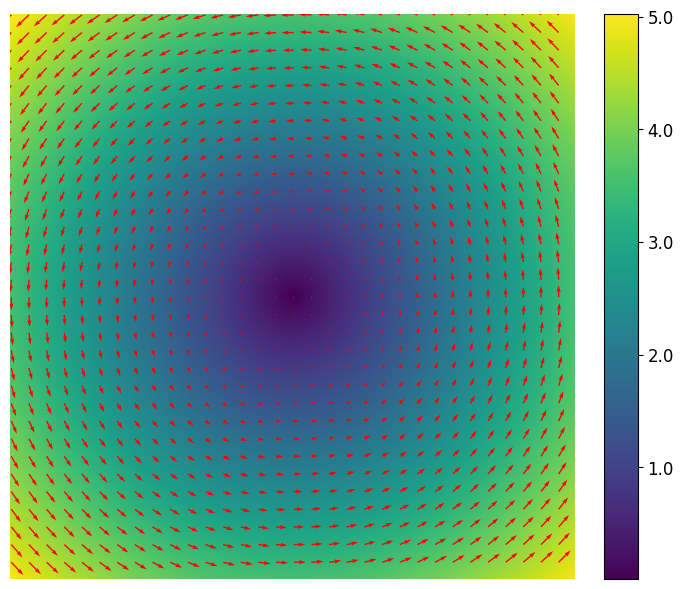

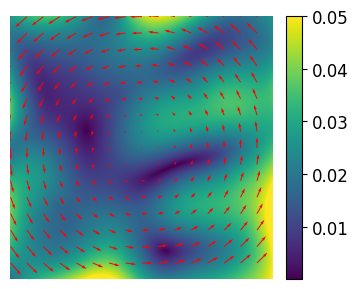

In [11]:
pred_u, pred_v = pred_uv[1], pred_uv[0]
PIVmetric(pred_u, pred_v, u_gt, v_gt)
# i, j = 16, 240
# PIVmetric(pred_u[i:j, i:j], pred_v[i:j, i:j], u_gt[i:j, i:j], v_gt[i:j, i:j])
plot_flow_field(pred_u, pred_v, output_file=None, v_max = None, colorbar_flag=True, step=1, quiver_step=8, scale=None, slFlag=False, figsize=(10, 6))
plot_flow_field(pred_u, pred_v, u_gt, v_gt, output_file=None, v_max = 0.05, colorbar_flag=True, step=1, quiver_step=16, scale=None, slFlag=False, figsize=(5, 3))

MODEL STATISTICS REPORT (N=80)

[1. Position (mu)]
  Range X: 20.34 ~ 246.25
  Range Y: 21.58 ~ 233.91
  Out of bounds: 0 / 80 (0.0%)

[2. Scale (pixels)]
  Min: 4.7172 | Max: 42.6667
  Mean: 35.7069 | Median: 40.4262
  Aspect Ratio (Long/Short): Mean=1.10, Max=1.66, Median=1.05

[3. Opacity (alpha)]
  Mean: 0.5429
  < 0.1 (Transparent): 0 count
  > 0.9 (Solid):       23 count

[4. Velocity Magnitude]
  Mean: 2.2763 | Max: 3.7811
  Min:  0.1164

[5. Jacobian Norm]
  Mean: 0.0404 | Max: 0.0553
(0, 2)


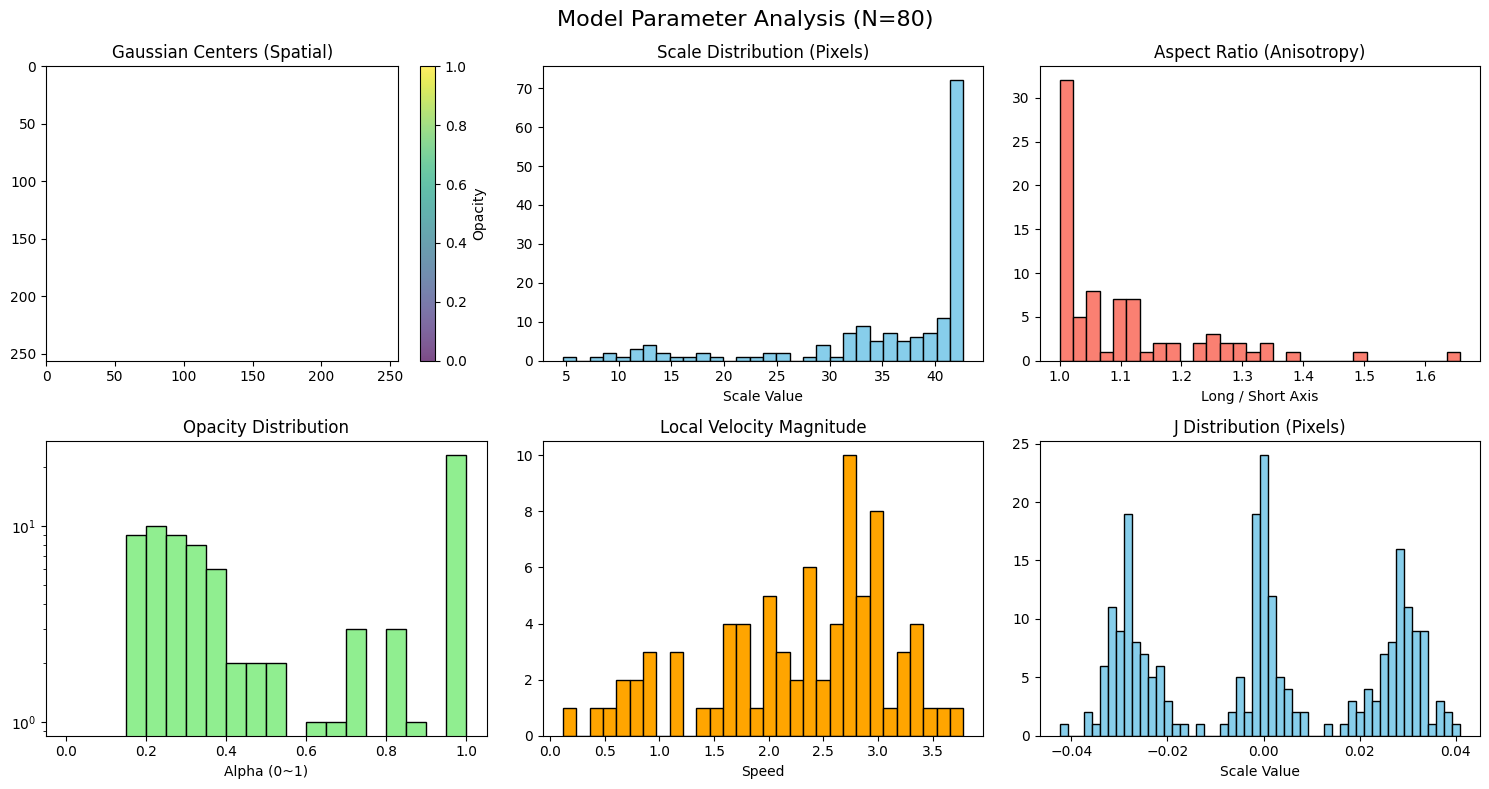

In [12]:
def analyze_model_stats(model):
    """
    全面分析训练后 GaussianVelocityField 模型的各项参数统计信息
    """
    print("="*60)
    print(f"MODEL STATISTICS REPORT (N={model.num_gaussians})")
    print("="*60)
    
    # 将数据移回 CPU 并转为 NumPy
    with torch.no_grad():
        mu = model.mu.detach().cpu().numpy()
        log_scale = model.log_scale.detach().cpu().numpy()
        scales = np.exp(log_scale)
        rotation = model.rotation.detach().cpu().numpy()
        opacity = torch.sigmoid(model.opacity_logit).detach().cpu().numpy()
        velocity = model.local_velocity.detach().cpu().numpy()
        J = model.J_params.detach().cpu().numpy()

    # --- 1. 位置 (Position) ---
    print(f"\n[1. Position (mu)]")
    print(f"  Range X: {mu[:, 1].min():.2f} ~ {mu[:, 1].max():.2f}")
    print(f"  Range Y: {mu[:, 0].min():.2f} ~ {mu[:, 0].max():.2f}")
    # 检查有多少跑出画布外
    out_bound = ((mu[:,0]<0)|(mu[:,0]>model.H)|(mu[:,1]<0)|(mu[:,1]>model.W)).sum()
    print(f"  Out of bounds: {out_bound} / {model.num_gaussians} ({out_bound/model.num_gaussians*100:.1f}%)")

    # --- 2. 尺度 (Scale) ---
    print(f"\n[2. Scale (pixels)]")
    print(f"  Min: {scales.min():.4f} | Max: {scales.max():.4f}")
    print(f"  Mean: {scales.mean():.4f} | Median: {np.median(scales):.4f}")
    
    # 长宽比 (Anisotropy)
    aspect_ratios = np.max(scales, axis=1) / np.min(scales, axis=1)
    print(f"  Aspect Ratio (Long/Short): Mean={aspect_ratios.mean():.2f}, Max={aspect_ratios.max():.2f}, Median={np.median(aspect_ratios):.2f}")
    if aspect_ratios.max() > 10:
        print("  WARNING: 存在极度细长的高斯，可能导致渲染伪影。")

    # --- 3. 不透明度 (Opacity) ---
    print(f"\n[3. Opacity (alpha)]")
    print(f"  Mean: {opacity.mean():.4f}")
    print(f"  < 0.1 (Transparent): {(opacity < 0.1).sum()} count")
    print(f"  > 0.9 (Solid):       {(opacity > 0.9).sum()} count")
    # 理想情况下，opacity 应该是两极分化的（要么很有用，要么没用）

    # --- 4. 速度 (Velocity) ---
    vel_mag = np.linalg.norm(velocity, axis=1)
    print(f"\n[4. Velocity Magnitude]")
    print(f"  Mean: {vel_mag.mean():.4f} | Max: {vel_mag.max():.4f}")
    print(f"  Min:  {vel_mag.min():.4f}")

    # --- 5. 雅可比 (Jacobian) ---
    J_mag = np.linalg.norm(J, axis=1) # Frobenius norm
    print(f"\n[5. Jacobian Norm]")
    print(f"  Mean: {J_mag.mean():.4f} | Max: {J_mag.max():.4f}")

    print("="*60)
    
    # ==========================================
    # 可视化绘图
    # ==========================================
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    fig.suptitle(f'Model Parameter Analysis (N={model.num_gaussians})', fontsize=16)

    # Plot 1: 空间分布散点图
    ax = axes[0, 0]
    ax.set_title("Gaussian Centers (Spatial)")
    # 根据 Opacity 设置颜色深浅
    mask = np.max(scales, axis=1) < 1
    mu_m = mu[mask]
    print(mu_m.shape)
    opacity_m = opacity[mask]
    sc = ax.scatter(mu_m[:, 1], mu_m[:, 0], c=opacity_m, cmap='viridis', s=10, alpha=0.7)
    ax.set_xlim(0, model.W)
    ax.set_ylim(0, model.H)
    ax.invert_yaxis() # 图像坐标系 Y 轴向下
    plt.colorbar(sc, ax=ax, label='Opacity')

    # Plot 2: 尺度分布 (直方图)
    ax = axes[0, 1]
    scales_mask = scales.flatten()[scales.flatten() < 2000]
    ax.set_title("Scale Distribution (Pixels)")
    ax.hist(scales_mask, bins=30, color='skyblue', edgecolor='black')
    ax.set_xlabel("Scale Value")

    # Plot 3: 长宽比分布
    ax = axes[0, 2]
    aspect_ratios = aspect_ratios[aspect_ratios < 10]
    ax.set_title("Aspect Ratio (Anisotropy)")
    ax.hist(aspect_ratios, bins=30, color='salmon', edgecolor='black')
    ax.set_xlabel("Long / Short Axis")

    # Plot 4: 不透明度分布
    ax = axes[1, 0]
    ax.set_title("Opacity Distribution")
    ax.hist(opacity.flatten(), bins=20, range=(0,1), color='lightgreen', edgecolor='black')
    ax.set_xlabel("Alpha (0~1)")
    ax.set_yscale('log') # 使用对数坐标，因为通常 0 附近的数量极大

    # Plot 5: 速度幅度分布
    ax = axes[1, 1]
    ax.set_title("Local Velocity Magnitude")
    ax.hist(vel_mag, bins=30, color='orange', edgecolor='black')
    ax.set_xlabel("Speed")

    # Plot 6: 旋转角度分布
    ax = axes[1, 2]
    # ax.set_title("Rotation (Degrees)")
    # # 将弧度转为度，并映射到 0-180 (因为椭圆旋转具有对称性)
    # deg = (np.degrees(rotation) % 180).flatten()
    # ax.hist(deg, bins=36, range=(0, 180), color='purple', edgecolor='black')
    # ax.set_xlabel("Angle (0-180)")
    J_mask = J.flatten()[J.flatten() < 20]
    ax.set_title("J Distribution (Pixels)")
    ax.hist(J_mask, bins=50, color='skyblue', edgecolor='black')
    ax.set_xlabel("Scale Value")

    plt.tight_layout()
    plt.show()

# 使用方法：
analyze_model_stats(model)

Flow-Weight相关性: 4.781  (越高越好，理想>0.3)
Weight粗糙度:      0.0318 (越低越连贯，理想<0.05)
覆盖变异系数CV:    0.435       (越低越均匀，理想<0.5)


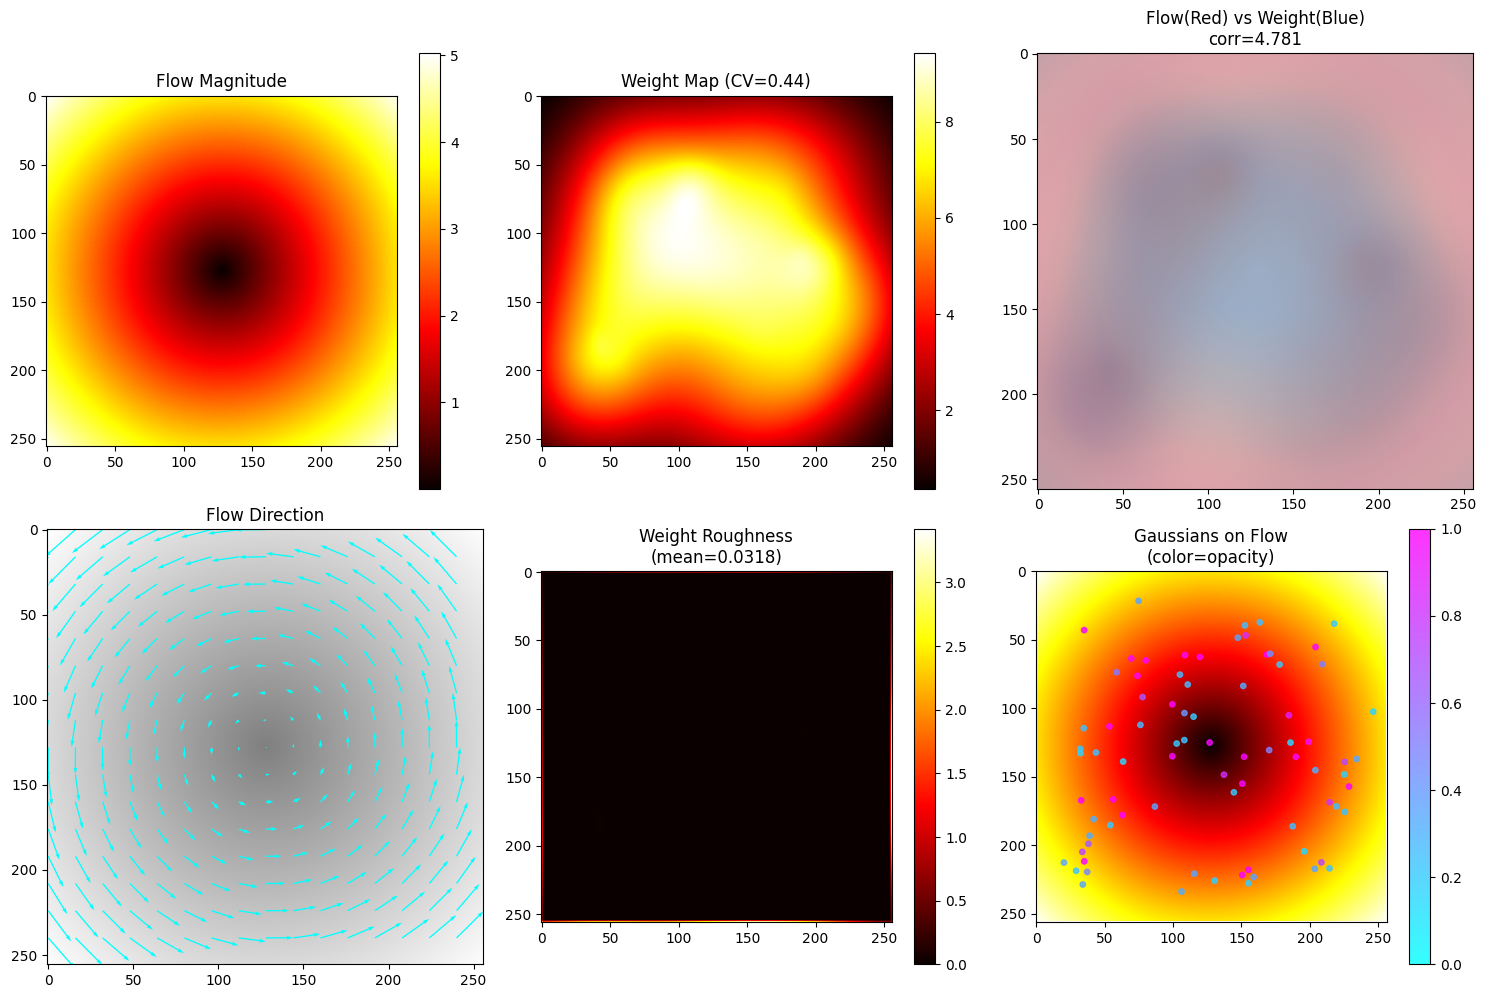

In [13]:
def visualize_coherence(model, pred_flow, weight_map, events=None):

    device = model.mu.device
    H, W = model.H, model.W

    with torch.no_grad():
        flow = pred_flow.detach().cpu()         # [2, H, W]
        wmap = weight_map.squeeze().detach().cpu()

        # ── 指标1：flow与weight的相关性 ──────────────────────
        # 流场幅值大的地方，weight应该也高（高斯在活跃区域聚集）
        flow_mag  = flow.norm(dim=0)            # [H, W]
        wmap_norm = (wmap - wmap.min()) / (wmap.max() - wmap.min() + 1e-6)
        mag_norm  = (flow_mag - flow_mag.min()) / (flow_mag.max() - flow_mag.min() + 1e-6)
        corr = (wmap_norm * mag_norm).mean() / (
            wmap_norm.std() * mag_norm.std() + 1e-6
        )

        # ── 指标2：weight_map平滑度（低=分块/碎片，高=连贯）──
        wmap_t    = wmap.unsqueeze(0).unsqueeze(0)
        laplacian = torch.tensor(
            [[0,1,0],[1,-4,1],[0,1,0]], dtype=torch.float32
        ).view(1,1,3,3)
        roughness = F.conv2d(wmap_t, laplacian, padding=1).abs().mean().item()

        # ── 指标3：coverage均匀性（变异系数）────────────────
        cv = wmap.std() / (wmap.mean() + 1e-6)

        print(f"Flow-Weight相关性: {corr:.3f}  (越高越好，理想>0.3)")
        print(f"Weight粗糙度:      {roughness:.4f} (越低越连贯，理想<0.05)")
        print(f"覆盖变异系数CV:    {cv:.3f}       (越低越均匀，理想<0.5)")

        # ── 可视化 ───────────────────────────────────────────
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))

        # 1. flow幅值
        ax = axes[0, 0]
        im = ax.imshow(flow_mag.numpy(), cmap='hot')
        ax.set_title('Flow Magnitude')
        plt.colorbar(im, ax=ax)

        # 2. weight_map
        ax = axes[0, 1]
        im = ax.imshow(wmap.numpy(), cmap='hot')
        ax.set_title(f'Weight Map (CV={cv:.2f})')
        plt.colorbar(im, ax=ax)

        # 3. flow幅值 vs weight 叠加对比
        ax = axes[0, 2]
        ax.imshow(mag_norm.numpy(), cmap='Reds', alpha=0.6)
        ax.imshow(wmap_norm.numpy(), cmap='Blues', alpha=0.4)
        ax.set_title(f'Flow(Red) vs Weight(Blue)\ncorr={corr:.3f}')

        # 4. flow方向箭头（稀疏采样）
        ax = axes[1, 0]
        step = 16
        y = torch.arange(0, H, step)
        x = torch.arange(0, W, step)
        gy, gx = torch.meshgrid(y, x, indexing='ij')
        u = flow[0, gy, gx].numpy()   # x方向
        v = flow[1, gy, gx].numpy()   # y方向
        ax.imshow(flow_mag.numpy(), cmap='gray', alpha=0.5)
        ax.quiver(gx.numpy(), gy.numpy(), u, -v,
                  scale=50, color='cyan', width=0.003)
        ax.set_title('Flow Direction')

        # 5. weight roughness map（局部粗糙度）
        ax = axes[1, 1]
        rough_map = F.conv2d(wmap_t, laplacian, padding=1).abs().squeeze()
        im = ax.imshow(rough_map.numpy(), cmap='hot')
        ax.set_title(f'Weight Roughness\n(mean={roughness:.4f})')
        plt.colorbar(im, ax=ax)

        # 6. 高斯中心叠加在flow上
        ax = axes[1, 2]
        ax.imshow(mag_norm.numpy(), cmap='hot')
        mu_np = model.mu.detach().cpu().numpy()
        op_np = torch.sigmoid(model.opacity_logit).squeeze().detach().cpu().numpy()
        sc = ax.scatter(mu_np[:, 1], mu_np[:, 0],
                        c=op_np, cmap='cool',
                        s=15, alpha=0.8, vmin=0, vmax=1)
        plt.colorbar(sc, ax=ax)
        ax.set_title('Gaussians on Flow\n(color=opacity)')
        ax.set_xlim(0, W)
        ax.set_ylim(H, 0)

        plt.tight_layout()
        plt.show()

visualize_coherence(model, torch.tensor(pred_uv), weight_map, events)

        速度区间            像素数        平均EPE       相对误差(EPE/v)   
--------------------------------------------------------------
  [ 0.00,  1.00)      4117       0.0159           0.0239
  [ 1.00,  2.00)     12352       0.0156           0.0100
  [ 2.00,  3.00)     20588       0.0199           0.0078
  [ 3.00,  4.00)     22682       0.0254           0.0074
  [ 4.00,  5.00)      5796       0.0274           0.0063


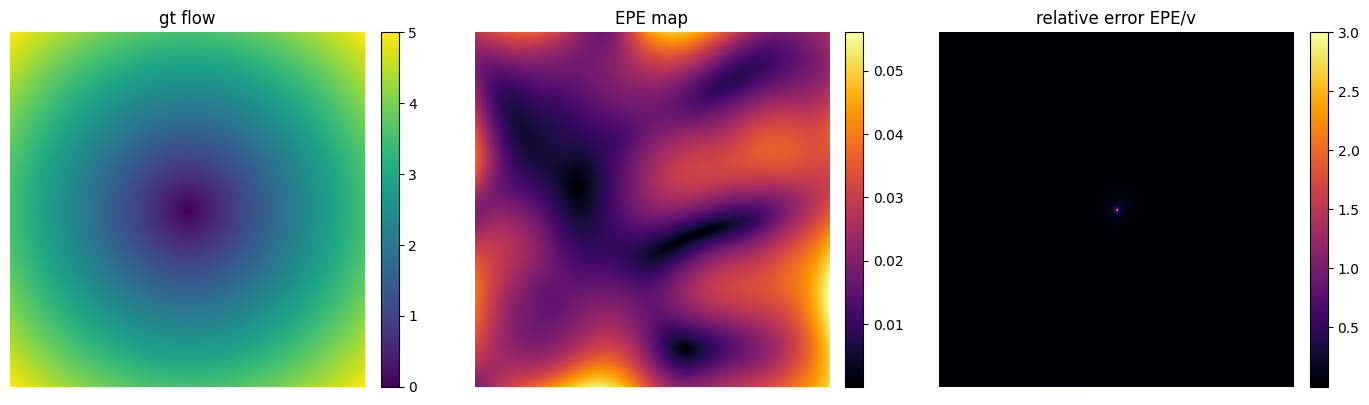

In [14]:
def analyze_error_by_velocity(pred_flow, gt_flow, n_bins=5):
    """
    按真值速度大小分区，统计每个速度区间的平均EPE。
    pred_flow, gt_flow: [2, H, W]
    """
    # 真值速度模长
    gt_mag  = gt_flow.norm(dim=0)          # [H, W]
    
    # EPE
    epe_map = (pred_flow - gt_flow).norm(dim=0)  # [H, W]

    # 按速度大小分bin
    v_min = gt_mag.min().item()
    v_max = gt_mag.max().item()
    bins  = torch.linspace(v_min, v_max, n_bins + 1)

    print(f"{'速度区间':^20} {'像素数':^10} {'平均EPE':^12} {'相对误差(EPE/v)':^16}")
    print("-" * 62)

    for i in range(n_bins):
        lo   = bins[i].item()
        hi   = bins[i+1].item()
        mask = (gt_mag >= lo) & (gt_mag < hi)
        if mask.sum() == 0:
            continue
        avg_epe = epe_map[mask].mean().item()
        avg_v   = gt_mag[mask].mean().item()
        rel_err = avg_epe / (avg_v + 1e-6)
        n_pix   = mask.sum().item()
        print(f"  [{lo:5.2f}, {hi:5.2f})  {n_pix:>8}   {avg_epe:>10.4f}   {rel_err:>14.4f}")

    # 可视化
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    def show(ax, img, title, cmap='viridis'):
        if isinstance(img, torch.Tensor):
            img = img.detach().cpu().numpy()
        im = ax.imshow(img, cmap=cmap, origin='upper')
        ax.set_title(title)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        ax.axis('off')

    show(axes[0], gt_mag,  "gt flow",   cmap='viridis')
    show(axes[1], epe_map, "EPE map",         cmap='inferno')

    # 相对误差图：EPE / 真值速度
    rel_err_map = epe_map / (gt_mag + 1e-6)
    rel_err_map = rel_err_map.clamp(0, 3)
    show(axes[2], rel_err_map, "relative error EPE/v", cmap='inferno')

    plt.tight_layout()
    plt.show()

analyze_error_by_velocity(torch.tensor(pred_uv).to(device), flowgt, n_bins=5)